Manual Processor of pipeline and column handling


In [159]:
import pandas as pd
pd.set_option('display.max_columns', None)
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

EDA

In [160]:
try:
    df = pd.read_csv(r'/home/mukul/Main/Basic_DataScience-4ML/assets/data/covid_toy.csv', index_col= None,
     usecols=['age','gender','cough','city','has_covid'],
     header = 0,
     engine='python',
     on_bad_lines='skip'
                     )
except Exception as e:
    print(e)

In [161]:
df.sample(10)

,age,gender,cough,city,has_covid
37,55,Male,Mild,Kolkata,No
46,19,Female,Mild,Mumbai,No
34,74,Male,Mild,Mumbai,Yes
93,27,Male,Mild,Kolkata,Yes
71,75,Female,Strong,Delhi,No
69,73,Female,Mild,Delhi,No
89,46,Male,Strong,Bangalore,No
65,69,Female,Mild,Bangalore,No
95,12,Female,Mild,Bangalore,No
16,69,Female,Mild,Kolkata,Yes


In [162]:
df.info()
df.describe()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100 entries, 0 to 99
Data columns (total 5 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   age        100 non-null    int64 
 1   gender     100 non-null    object
 2   cough      100 non-null    object
 3   city       100 non-null    object
 4   has_covid  100 non-null    object
dtypes: int64(1), object(4)
memory usage: 4.0+ KB


,age
count,100.000000
mean,44.220000
std,24.878931
min,5.000000
25%,20.000000
50%,45.000000
75%,66.500000
max,84.000000


In [163]:
df["city"].value_counts()

city
Kolkata      32
Bangalore    30
Delhi        22
Mumbai       16
Name: count, dtype: int64

In [164]:
import os
import ydata_profiling
from ydata_profiling import ProfileReport


In [165]:
pr = ProfileReport(df)
if os.path.isfile('report.html'):
    os.remove('report.html')
else:
    pr.to_file('report.html')

Export report to file: 100%|██████████| 1/1 [00:00<00:00, 1495.30it/s]


<Axes: ylabel='age'>

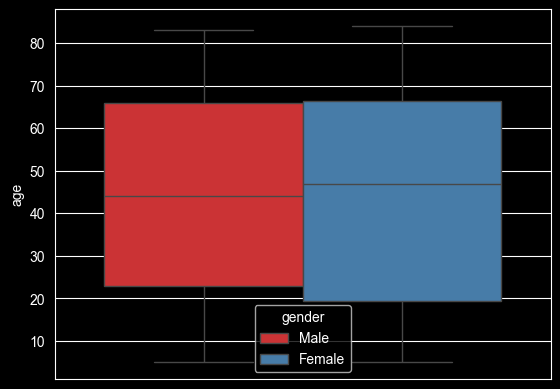

In [166]:
sns.boxplot(data=df, y='age',hue='gender',palette='Set1')

In [167]:
df.drop_duplicates(subset=['age'], inplace=True)
df.reset_index(inplace=True,drop=True)

In [168]:
pr = ProfileReport(df)
if os.path.isfile('report_afterEDA.html'):
    os.remove('report_afterEDA.html')
else:
    pr.to_file('report_afterEDA.html')

Export report to file: 100%|██████████| 1/1 [00:00<00:00, 1378.80it/s]


Feature Engineering

In [169]:
from sklearn.model_selection import  train_test_split
from sklearn.preprocessing import OrdinalEncoder , OneHotEncoder
from sklearn.preprocessing import StandardScaler

In [170]:
x = df.drop('has_covid',axis=1)
y = df[['has_covid']]
x_train,x_test,y_train,y_test = train_test_split(x,y,test_size=0.2,random_state=42)

In [171]:
x_train

,age,gender,cough,city
3,31,Female,Mild,Kolkata
33,50,Female,Mild,Kolkata
34,22,Female,Mild,Bangalore
8,19,Female,Strong,Bangalore
17,73,Male,Mild,Bangalore
6,14,Male,Strong,Bangalore
4,65,Female,Mild,Mumbai
47,68,Female,Strong,Delhi
27,26,Female,Mild,Kolkata
46,54,Female,Strong,Kolkata


In [172]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 55 entries, 0 to 54
Data columns (total 5 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   age        55 non-null     int64 
 1   gender     55 non-null     object
 2   cough      55 non-null     object
 3   city       55 non-null     object
 4   has_covid  55 non-null     object
dtypes: int64(1), object(4)
memory usage: 2.3+ KB


In [173]:
df['cough'].value_counts()

cough
Mild      33
Strong    22
Name: count, dtype: int64

In [174]:
x_test

,age,gender,cough,city
31,55,Male,Mild,Kolkata
5,84,Female,Mild,Bangalore
32,49,Female,Mild,Delhi
13,70,Male,Strong,Kolkata
19,80,Female,Mild,Delhi
49,8,Female,Mild,Kolkata
41,81,Female,Mild,Mumbai
26,83,Male,Mild,Kolkata
43,24,Female,Strong,Bangalore
12,51,Male,Mild,Bangalore


In [175]:
oe = OrdinalEncoder(categories=[['Mild','Strong']])
x_train_encoded = oe.fit_transform(x_train[['cough']])
x_test_encoded = oe.transform(x_test[['cough']])

In [176]:
x_train['cough'] = x_train_encoded
x_test['cough'] = x_test_encoded

In [177]:
x_train

,age,gender,cough,city
3,31,Female,0.0,Kolkata
33,50,Female,0.0,Kolkata
34,22,Female,0.0,Bangalore
8,19,Female,1.0,Bangalore
17,73,Male,0.0,Bangalore
6,14,Male,1.0,Bangalore
4,65,Female,0.0,Mumbai
47,68,Female,1.0,Delhi
27,26,Female,0.0,Kolkata
46,54,Female,1.0,Kolkata


In [178]:
ohe = OneHotEncoder()

x_train_encoded = ohe.fit_transform(
    x_train[['city', 'gender']]
).toarray()

x_test_encoded = ohe.transform(
    x_test[['city', 'gender']]
).toarray()

x_train_encoded = pd.DataFrame(
    x_train_encoded,
    columns=ohe.get_feature_names_out(['city', 'gender']),
    index=x_train.index
)

x_test_encoded = pd.DataFrame(
    x_test_encoded,
    columns=ohe.get_feature_names_out(['city', 'gender']),
    index=x_test.index
)

In [179]:
x_train = pd.concat(
    [
        x_train.drop(columns=['gender', 'city']),
        x_train_encoded
    ],
    axis=1
)

In [180]:
x_train

,age,cough,city_Bangalore,city_Delhi,city_Kolkata,city_Mumbai,gender_Female,gender_Male
3,31,0.0,0.0,0.0,1.0,0.0,1.0,0.0
33,50,0.0,0.0,0.0,1.0,0.0,1.0,0.0
34,22,0.0,1.0,0.0,0.0,0.0,1.0,0.0
8,19,1.0,1.0,0.0,0.0,0.0,1.0,0.0
17,73,0.0,1.0,0.0,0.0,0.0,0.0,1.0
6,14,1.0,1.0,0.0,0.0,0.0,0.0,1.0
4,65,0.0,0.0,0.0,0.0,1.0,1.0,0.0
47,68,1.0,0.0,1.0,0.0,0.0,1.0,0.0
27,26,0.0,0.0,0.0,1.0,0.0,1.0,0.0
46,54,1.0,0.0,0.0,1.0,0.0,1.0,0.0
